In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append("..")
from pathlib import Path
from src.data.data import build_auctions

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

COLORS = {"upwards": "tab:blue", "downwards": "tab:orange"}
DIRECTIONS = ["upwards", "downwards"]

In [2]:
PRODUCT = "mFRR"
all_auctions = build_auctions(product=PRODUCT)          # team table: src/data/data.py (daily + weekly)
# correction auctions (KORR): see the weekly notebook and questions.txt
all_auctions = all_auctions[~all_auctions["auction_id"].str.contains("KORR")].reset_index(drop=True)
all_auctions["date"] = pd.to_datetime(all_auctions["date"])

auctions = all_auctions[all_auctions["freq"] == "daily"].reset_index(drop=True)
BLOCKS = sorted(auctions["block"].unique())

print("daily auctions per direction:", auctions.groupby("direction").size().to_dict())
print("blocks:", BLOCKS)
print("no-buy auctions (no price):", auctions["y"].isna().sum())

daily auctions per direction: {'downwards': 17040, 'upwards': 17034}
blocks: ['00_04', '04_08', '08_12', '12_16', '16_20', '20_24']
no-buy auctions (no price): 5425


In [3]:
# marginal price (CHF/MW, auctions with a price only) by direction and by block
auctions.groupby("direction")["marginal"].describe()

,count,mean,std,min,25%,50%,75%,max
direction,,,,,,,,
downwards,14033.0,66.969079,146.389549,0.03,4.71,15.7,60.0000,2438.00
upwards,14616.0,15.863393,46.946938,0.01,1.80,5.2,14.3425,1737.78


In [4]:
auctions.pivot_table(index="block", columns="direction", values="marginal", aggfunc="median").round(1)

direction,downwards,upwards
block,,
00_04,18.0,1.9
04_08,17.6,4.5
08_12,16.4,8.0
12_16,31.5,4.0
16_20,13.5,11.0
20_24,9.0,8.0


## 1. No-buy auctions

The statement warns that no-buy auctions are not random. When are they?

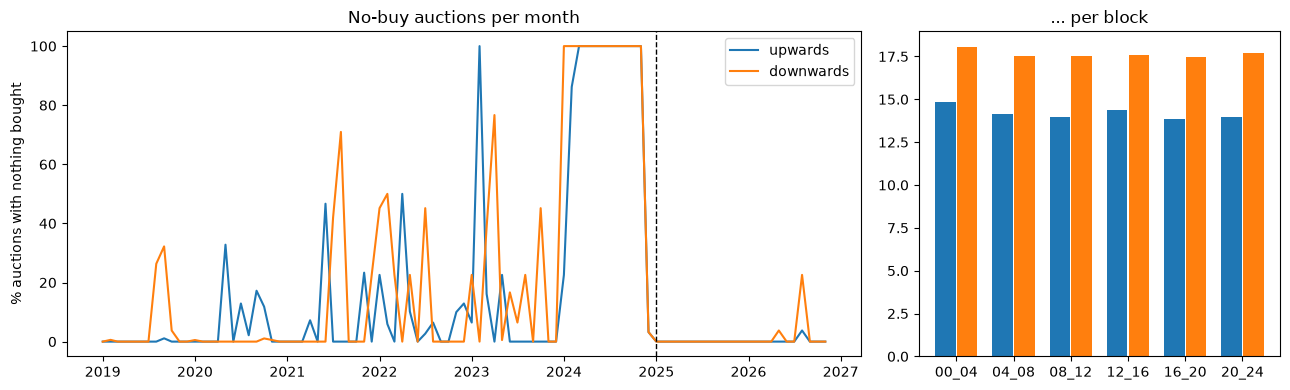

In [5]:
auctions["no_buy"] = auctions["y"].isna()
auctions["month"] = auctions["date"].dt.to_period("M").dt.to_timestamp()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[2.2, 1]))

for direction in DIRECTIONS:
    d = auctions[auctions["direction"] == direction]
    share = d.groupby("month")["no_buy"].mean()
    ax1.plot(share.index, 100 * share.values, color=COLORS[direction], label=direction)

    by_block = d.groupby("block")["no_buy"].mean().reindex(BLOCKS)
    k = DIRECTIONS.index(direction)
    ax2.bar(np.arange(len(BLOCKS)) + (k - 0.5) * 0.38, 100 * by_block.values, width=0.36,
            color=COLORS[direction], label=direction)

ax1.axvline(pd.Timestamp("2025-01-01"), color="black", linestyle="--", linewidth=1)
ax1.set_ylabel("% auctions with nothing bought")
ax1.set_title("No-buy auctions per month")
ax1.legend()
ax2.set_xticks(range(len(BLOCKS)), BLOCKS)
ax2.set_title("... per block")
fig.tight_layout()
fig.savefig(FIG / "daily_fig1_no_buy.png", dpi=150, bbox_inches="tight")

In [6]:
# do daily no-buy auctions happen in weeks when the weekly auction bought more?
a = all_auctions.copy()
a["week"] = a["date"].dt.to_period("W-SUN").dt.start_time
weekly_vol = a[a["freq"] == "weekly"].groupby(["direction", "week"])["awarded"].sum().rename("weekly_awarded")
daily_week = a[a["freq"] == "daily"].groupby(["direction", "week"]).agg(nobuy_share=("y", lambda y: y.isna().mean()))
check = daily_week.join(weekly_vol).reset_index()
check["year"] = check["week"].dt.year

print("Spearman, all weeks:")
print(check.groupby("direction")[["weekly_awarded", "nobuy_share"]].corr(method="spearman").xs("nobuy_share", level=1)["weekly_awarded"].round(2))
print("\nSpearman within each year:")
check.groupby(["direction", "year"]).apply(
    lambda g: g["weekly_awarded"].corr(g["nobuy_share"], method="spearman")
).unstack("direction").round(2)

Spearman, all weeks:
direction
downwards    0.34
upwards      0.32
Name: weekly_awarded, dtype: float64

Spearman within each year:


/home/carolina-araujo/Documents/EPFL/Machine_Learning/Project/Swissgrid-reserve-price-forecast/.venv/lib/python3.14/site-packages/pandas/core/nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/home/carolina-araujo/Documents/EPFL/Machine_Learning/Project/Swissgrid-reserve-price-forecast/.venv/lib/python3.14/site-packages/pandas/core/nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


direction,downwards,upwards
year,,
2018,NaN,NaN
2019,0.47,0.33
2020,0.25,0.58
2021,0.44,0.45
2022,0.43,0.52
2023,0.12,-0.17
2024,0.25,0.89
2025,NaN,NaN
2026,0.32,0.21


## 2. Price through time

One point per auction would be unreadable (≈ 2,200 per direction and year), so: daily median over the 6 blocks,
and its 28-day rolling median.

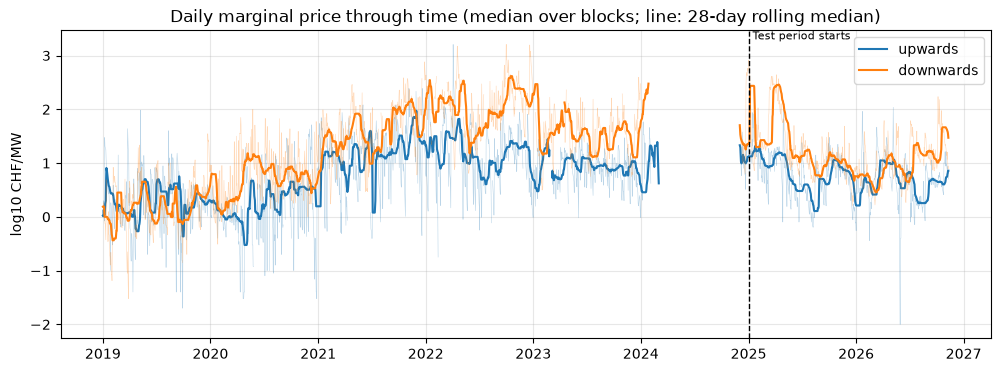

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))

for direction in DIRECTIONS:
    d = auctions[auctions["direction"] == direction]
    per_day = d.groupby("date")["y"].median()
    ax.plot(per_day.index, per_day.values, color=COLORS[direction], linewidth=0.4, alpha=0.3)
    ax.plot(per_day.rolling("28D").median(), color=COLORS[direction], linewidth=1.5, label=direction)

ax.axvline(pd.Timestamp("2025-01-01"), color="black", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2025-01-01"), ax.get_ylim()[1], " Test period starts", va="top", fontsize=8)
ax.set_title("Daily marginal price through time (median over blocks; line: 28-day rolling median)")
ax.set_ylabel("log10 CHF/MW")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(FIG / "daily_fig2_price_time.png", dpi=150, bbox_inches="tight")

## 3. Distribution

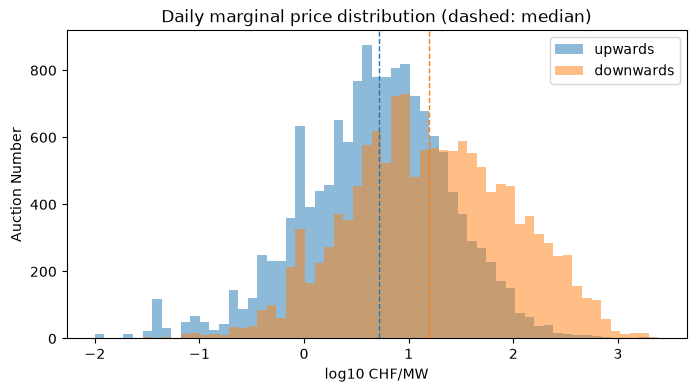

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(auctions["y"].min(), auctions["y"].max(), 60)

for direction in DIRECTIONS:
    d = auctions[auctions["direction"] == direction]["y"].dropna()
    ax.hist(d, bins=bins, alpha=0.5, color=COLORS[direction], label=direction)
    ax.axvline(d.median(), color=COLORS[direction], linestyle="--", linewidth=1)

ax.set_xlabel("log10 CHF/MW")
ax.set_ylabel("Auction Number")
ax.set_title("Daily marginal price distribution (dashed: median)")
ax.legend()
fig.savefig(FIG / "daily_fig3_distribution.png", dpi=150, bbox_inches="tight")

## 4. Block × day-of-week effect

Median log10 price per block and day of the week, minus the median of the direction:
the pattern, not the level. Then workday / Saturday / Sunday-holiday.

/tmp/ipykernel_72635/1639279638.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  auctions["dow"] = auctions["date"].dt.dayofweek


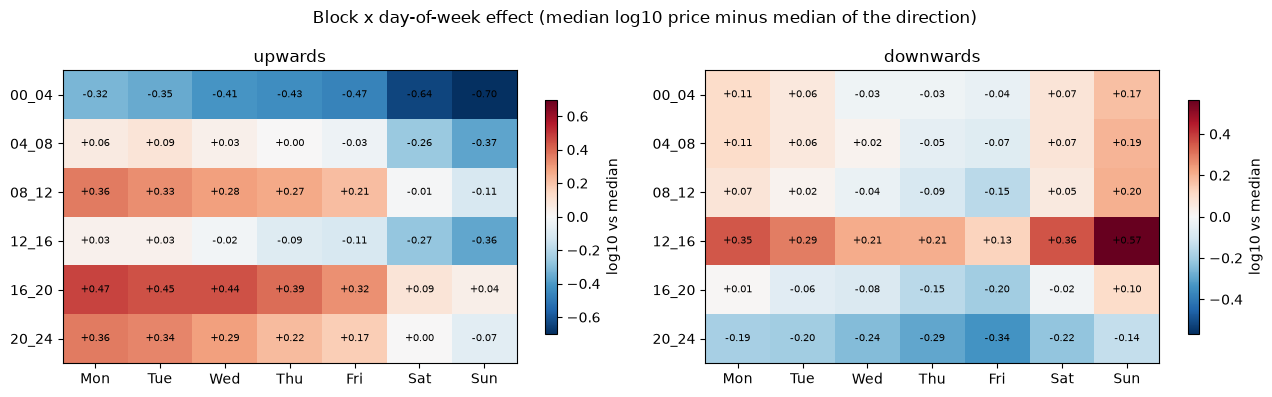

In [9]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
auctions["dow"] = auctions["date"].dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, direction in zip(axes, DIRECTIONS):
    d = auctions[auctions["direction"] == direction]
    dev = d.pivot_table(index="block", columns="dow", values="y", aggfunc="median").reindex(BLOCKS) - d["y"].median()
    lim = np.nanmax(np.abs(dev.to_numpy()))
    im = ax.imshow(dev, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for (r, c), v in np.ndenumerate(dev.to_numpy()):
        if not np.isnan(v):
            ax.text(c, r, f"{v:+.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(7), DOW)
    ax.set_yticks(range(len(BLOCKS)), BLOCKS)
    ax.set_title(direction)
    fig.colorbar(im, ax=ax, shrink=0.8, label="log10 vs median")
fig.suptitle("Block x day-of-week effect (median log10 price minus median of the direction)")
fig.tight_layout()
fig.savefig(FIG / "daily_fig4_block_dow.png", dpi=150, bbox_inches="tight")

In [10]:
# day type (workday / saturday / sunday_holiday), by direction: median log10 price
auctions.pivot_table(index="day_type", columns="direction", values="y", aggfunc="median").round(2)

direction,downwards,upwards
day_type,,
saturday,1.23,0.56
sunday_holiday,1.40,0.46
workday,1.15,0.82


## 5. Autocorrelation within a series

For each block series: correlation with the same block k days earlier (missing days and no-buy days are skipped
pair by pair). Line: mean over the 6 blocks; band: min–max.

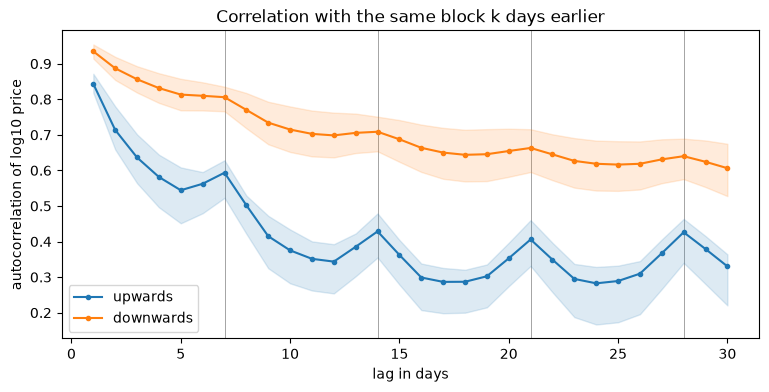

In [11]:
lags = range(1, 31)
fig, ax = plt.subplots(figsize=(9, 4))

for direction in DIRECTIONS:
    rows = []
    for block in BLOCKS:
        s = auctions[(auctions["direction"] == direction) & (auctions["block"] == block)].set_index("date")["y"]
        s = s[~s.index.duplicated()].asfreq("D")          # one value per calendar day, NaN when missing
        rows.append([s.autocorr(lag=k) for k in lags])
    acf = np.array(rows)
    ax.fill_between(lags, acf.min(axis=0), acf.max(axis=0), color=COLORS[direction], alpha=0.15)
    ax.plot(lags, acf.mean(axis=0), marker="o", markersize=3, color=COLORS[direction], label=direction)

for k in (7, 14, 21, 28):
    ax.axvline(k, color="gray", linewidth=0.5, zorder=0)
ax.set_xlabel("lag in days")
ax.set_ylabel("autocorrelation of log10 price")
ax.set_title("Correlation with the same block k days earlier")
ax.legend()
fig.savefig(FIG / "daily_fig5_autocorrelation.png", dpi=150, bbox_inches="tight")

## 6. Regimes per year

direction,downwards,upwards
date,,
2019,1.8,1.8
2020,5.9,1.2
2021,44.8,15.0
2022,116.0,13.9
2023,32.0,7.8
2024,25.0,11.4
2025,16.2,6.2
2026,8.4,4.8


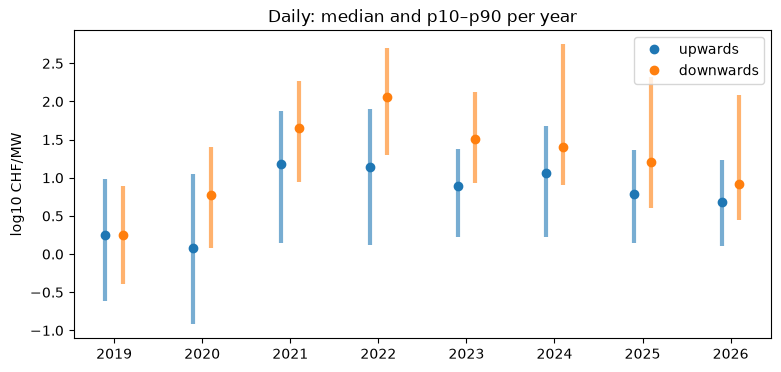

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))

for i, direction in enumerate(DIRECTIONS):
    d = auctions[auctions["direction"] == direction]
    q = d.groupby(d["date"].dt.year)["y"].quantile([0.1, 0.5, 0.9]).unstack()
    x = q.index + (i - 0.5) * 0.2
    ax.vlines(x, q[0.1], q[0.9], color=COLORS[direction], linewidth=3, alpha=0.6)
    ax.plot(x, q[0.5], "o", color=COLORS[direction], label=direction)

ax.set_xticks(sorted(auctions["date"].dt.year.unique()))
ax.set_ylabel("log10 CHF/MW")
ax.set_title("Daily: median and p10–p90 per year")
ax.legend()
fig.savefig(FIG / "daily_fig6_regimes.png", dpi=150, bbox_inches="tight")

auctions.pivot_table(index=auctions["date"].dt.year, columns="direction", values="marginal", aggfunc="median").round(1)

## 7. Daily vs weekly, per hour of delivery

A daily block covers 4 h, a weekly auction 168 h: prices are only comparable per hour of delivery
(daily price / 4, weekly price / 168). Monthly medians.

freq,daily,weekly
direction,,
downwards,3.925,6.569
upwards,1.300,2.190


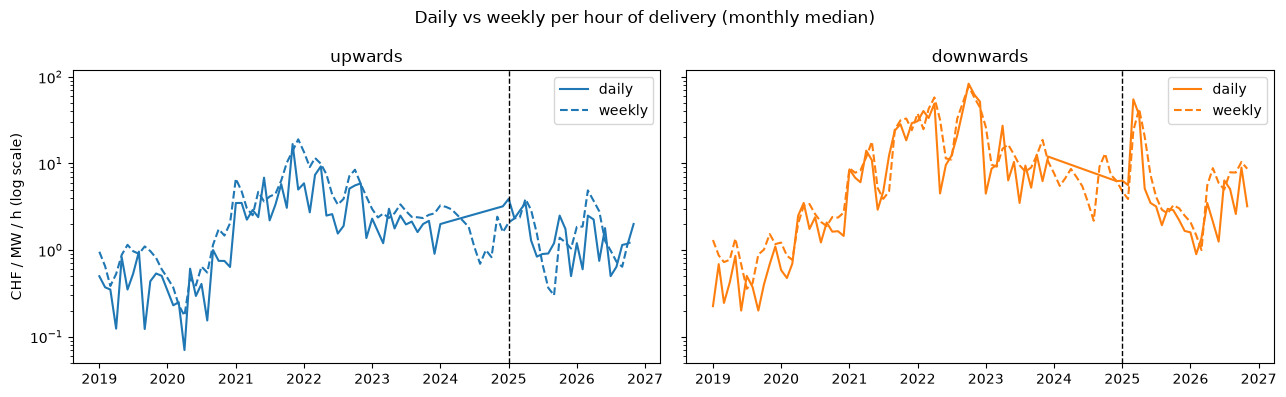

In [13]:
HOURS = {"daily": 4, "weekly": 168}
both = all_auctions[all_auctions["y"].notna()].copy()
both["price_per_hour"] = both["marginal"] / both["freq"].map(HOURS)
both["month"] = both["date"].dt.to_period("M").dt.to_timestamp()
monthly = both.groupby(["direction", "freq", "month"])["price_per_hour"].median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, direction in zip(axes, DIRECTIONS):
    for freq, ls in [("daily", "-"), ("weekly", "--")]:
        m = monthly.loc[(direction, freq)]
        ax.plot(m.index, m.values, ls, color=COLORS[direction], label=freq)
    ax.set_yscale("log")
    ax.axvline(pd.Timestamp("2025-01-01"), color="black", linestyle="--", linewidth=1)
    ax.set_title(direction)
    ax.legend()
axes[0].set_ylabel("CHF / MW / h (log scale)")
fig.suptitle("Daily vs weekly per hour of delivery (monthly median)")
fig.tight_layout()
fig.savefig(FIG / "daily_fig7_daily_vs_weekly.png", dpi=150, bbox_inches="tight")

both.groupby(["direction", "freq"])["price_per_hour"].median().unstack().round(3)

## 8. Upwards vs downwards (same day, same block)

They close in the same sitting, so this is about co-movement, not a usable feature.

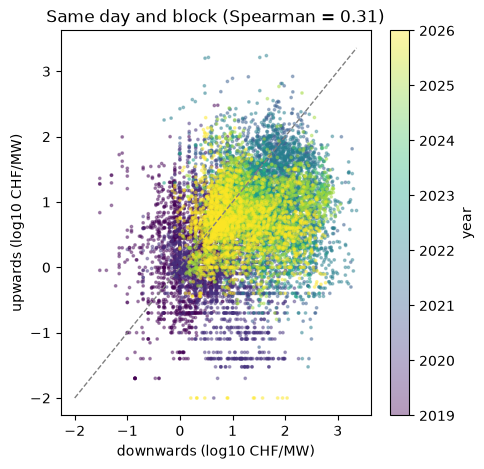

In [14]:
wide = auctions.pivot_table(index=["date", "block"], columns="direction", values="y", aggfunc="first").dropna()
year = wide.index.get_level_values("date").year

fig, ax = plt.subplots(figsize=(5, 5))
sc = ax.scatter(wide["downwards"], wide["upwards"], c=year, cmap="viridis", s=3, alpha=0.4)
lo, hi = np.nanmin(wide.values), np.nanmax(wide.values)
ax.plot([lo, hi], [lo, hi], color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("downwards (log10 CHF/MW)")
ax.set_ylabel("upwards (log10 CHF/MW)")
ax.set_title(f"Same day and block (Spearman = {wide.corr(method='spearman').iloc[0, 1]:.2f})")
fig.colorbar(sc, label="year")
fig.savefig(FIG / "daily_fig8_up_vs_down.png", dpi=150, bbox_inches="tight")

## 9. Competition: offered / awarded

In [15]:
auctions[["n_bids", "n_accepted", "offered", "awarded", "supply_ratio"]].describe()

,n_bids,n_accepted,offered,awarded,supply_ratio
count,34074.000000,34074.000000,34074.000000,34074.000000,28649.000000
mean,10.961848,3.743001,290.637935,61.825820,6.662667
std,5.690185,3.424875,146.903443,54.534546,7.380426
min,1.000000,0.000000,17.000000,0.000000,1.000000
25%,7.000000,1.000000,199.000000,21.000000,3.573529
50%,10.000000,3.000000,281.000000,50.000000,4.729167
75%,15.000000,6.000000,381.000000,85.000000,6.720000
max,32.000000,22.000000,903.000000,390.000000,123.800000


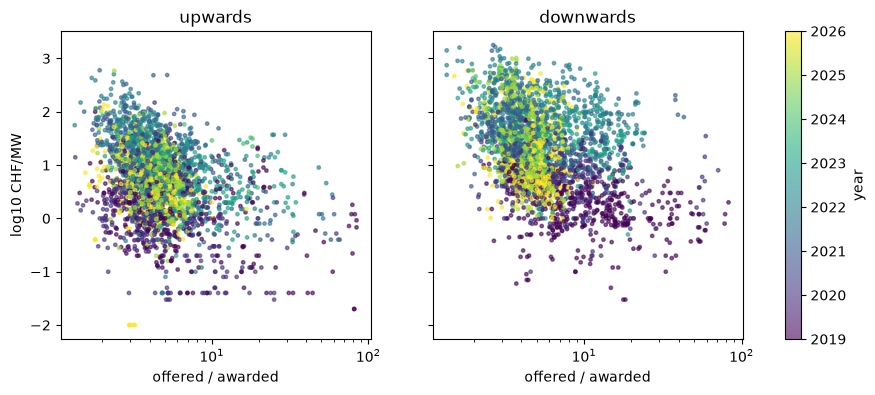

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, direction in zip(axes, DIRECTIONS):
    d = auctions[(auctions["direction"] == direction) & auctions["y"].notna()]
    d = d.sample(min(len(d), 3000), random_state=0)          # readable scatter
    sc = ax.scatter(d["supply_ratio"], d["y"], c=d["date"].dt.year, cmap="viridis", s=6, alpha=0.6)
    ax.set_xscale("log")
    ax.set_title(direction)
    ax.set_xlabel("offered / awarded")

axes[0].set_ylabel("log10 CHF/MW")
fig.colorbar(sc, ax=axes, label="year")
fig.savefig(FIG / "daily_fig9_price_vs_supply_ratio.png", dpi=150, bbox_inches="tight")

## 10. Month effect

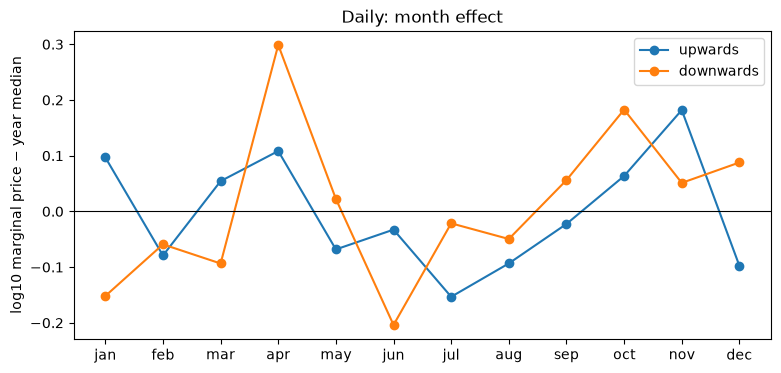

In [17]:
year_median = auctions.groupby(["direction", auctions["date"].dt.year])["y"].transform("median")
auctions["log10_vs_year"] = auctions["y"] - year_median

fig, ax = plt.subplots(figsize=(9, 4))
for direction in DIRECTIONS:
    d = auctions[auctions["direction"] == direction]
    m = d.groupby(d["date"].dt.month)["log10_vs_year"].median()
    ax.plot(m.index, m.values, marker="o", color=COLORS[direction], label=direction)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(1, 13), ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"])
ax.set_ylabel("log10 marginal price − year median")
ax.set_title("Daily: month effect")
ax.legend()
fig.savefig(FIG / "daily_fig10_seasonality.png", dpi=150, bbox_inches="tight")